# Differential Gene Expression: a Minimal Pipeline

Which genes differ between two conditions (e.g. healthy vs. tumour tissue)?
This notebook walks through the standard idea with a small **simulated** expression table:
normalise, test each gene, correct for multiple testing, visualise.

**Why simulated?** It makes the notebook self-contained and lets us check the result against the
known truth (we planted 100 truly changed genes). The same code structure applies to a real
expression matrix, e.g. from NCBI GEO (see last section).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(42)

## 1. Simulate a count matrix
2,000 genes, 6 control and 6 tumour samples. 100 genes are truly changed
(50 up, 50 down, roughly 2.5-fold).

In [2]:
n_genes, n_ctrl, n_tumor = 2000, 6, 6
genes = [f"GENE{i:04d}" for i in range(n_genes)]
samples = [f"ctrl_{i+1}" for i in range(n_ctrl)] + [f"tumor_{i+1}" for i in range(n_tumor)]

base_mean = rng.lognormal(mean=5, sigma=1.2, size=n_genes)   # gene-specific average expression
fold = np.ones(n_genes)
fold[:50] = 2.5          # truly up in tumour
fold[50:100] = 1 / 2.5   # truly down in tumour
is_de = np.zeros(n_genes, dtype=bool)
is_de[:100] = True

counts = np.empty((n_genes, n_ctrl + n_tumor), dtype=int)
for j in range(n_ctrl + n_tumor):
    mu = base_mean * (fold if j >= n_ctrl else 1)
    # negative binomial: realistic over-dispersion for count data
    r = 20
    counts[:, j] = rng.negative_binomial(r, r / (r + mu))

counts = pd.DataFrame(counts, index=genes, columns=samples)
counts.to_csv("simulated_counts.csv")
counts.iloc[:5, :6]

,ctrl_1,ctrl_2,ctrl_3,ctrl_4,ctrl_5,ctrl_6
GENE0000,191,159,166,202,216,208
GENE0001,36,35,52,40,77,50
GENE0002,265,165,532,222,488,360
GENE0003,433,381,419,484,565,483
GENE0004,28,14,17,15,6,12


## 2. Normalise
Library sizes differ between samples, so we scale to counts per million (CPM) and take log2.
This is a simple normalisation; real RNA-seq workflows use tools like DESeq2 or edgeR.

In [3]:
cpm = counts / counts.sum() * 1e6
log_cpm = np.log2(cpm + 1)

lib_sizes = counts.sum()
print(lib_sizes.round(0).astype(int).to_string())

ctrl_1     564736
ctrl_2     570723
ctrl_3     572855
ctrl_4     560308
ctrl_5     558674
ctrl_6     565447
tumor_1    582282
tumor_2    585296
tumor_3    575600
tumor_4    582655
tumor_5    571972
tumor_6    572081


## 3. Quality check: PCA of the samples

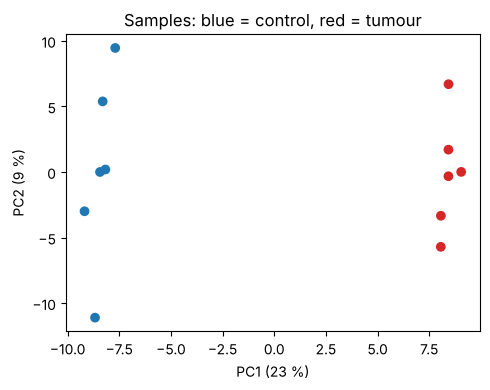

In [4]:
centered = log_cpm.T - log_cpm.T.mean()
u, s, vt = np.linalg.svd(centered, full_matrices=False)
pcs = u * s
var_expl = s**2 / (s**2).sum() * 100

colors = ["tab:blue"] * n_ctrl + ["tab:red"] * n_tumor
plt.figure(figsize=(5, 4))
plt.scatter(pcs[:, 0], pcs[:, 1], c=colors)
plt.xlabel(f"PC1 ({var_expl[0]:.0f} %)")
plt.ylabel(f"PC2 ({var_expl[1]:.0f} %)")
plt.title("Samples: blue = control, red = tumour")
plt.tight_layout()
plt.show()

## 4. Test every gene
Welch's t-test on log2 CPM per gene, log2 fold change as difference of group means,
and Benjamini-Hochberg correction for testing 2,000 genes at once.

In [5]:
ctrl = log_cpm.iloc[:, :n_ctrl]
tumor = log_cpm.iloc[:, n_ctrl:]

t_stat, p_val = stats.ttest_ind(tumor, ctrl, axis=1, equal_var=False)
res = pd.DataFrame({
    "log2FC": tumor.mean(axis=1) - ctrl.mean(axis=1),
    "p_value": p_val,
}, index=log_cpm.index)
res["padj"] = multipletests(res["p_value"], method="fdr_bh")[1]
res["significant"] = (res["padj"] < 0.05) & (res["log2FC"].abs() > 1)
res.sort_values("padj").head(10)

,log2FC,p_value,padj,significant
GENE0000,1.412888,9.462327e-07,0.000315,True
GENE0071,-2.075633,8.941596e-07,0.000315,True
GENE0026,1.529947,3.578570e-07,0.000315,True
GENE0011,1.766152,7.323346e-07,0.000315,True
GENE0053,-1.463751,9.433464e-07,0.000315,True
GENE0057,-1.811613,8.851665e-07,0.000315,True
GENE0020,1.309559,2.127887e-06,0.000484,True
GENE0010,1.751308,1.962984e-06,0.000484,True
GENE0069,-1.813914,2.179617e-06,0.000484,True
GENE0093,-1.262427,6.626031e-06,0.001042,True


## 5. Volcano plot

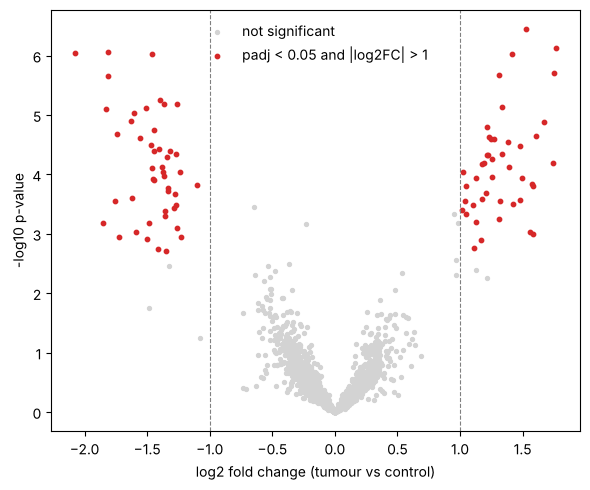

Significant genes: 90 (up: 44 , down: 46 )


In [6]:
plt.figure(figsize=(6, 5))
ns = ~res["significant"]
plt.scatter(res.loc[ns, "log2FC"], -np.log10(res.loc[ns, "p_value"]), s=8, c="lightgrey", label="not significant")
sig = res["significant"]
plt.scatter(res.loc[sig, "log2FC"], -np.log10(res.loc[sig, "p_value"]), s=10, c="tab:red", label="padj < 0.05 and |log2FC| > 1")
plt.axvline(-1, ls="--", c="grey", lw=0.8)
plt.axvline(1, ls="--", c="grey", lw=0.8)
plt.xlabel("log2 fold change (tumour vs control)")
plt.ylabel("-log10 p-value")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("volcano_plot.png", dpi=150)
plt.show()

print("Significant genes:", int(sig.sum()), "(up:", int((res.loc[sig, 'log2FC'] > 0).sum()),
      ", down:", int((res.loc[sig, 'log2FC'] < 0).sum()), ")")

## 6. Check against the truth
Because we simulated the data we know which genes are truly changed.
How many did we recover, and how many false positives did we call?

In [7]:
tp = int((res["significant"] & is_de).sum())
fp = int((res["significant"] & ~is_de).sum())
fn = int((~res["significant"] & is_de).sum())
print(f"True positives: {tp}   False positives: {fp}   Missed: {fn}")

True positives: 90   False positives: 0   Missed: 10


## 7. Top genes as a heatmap

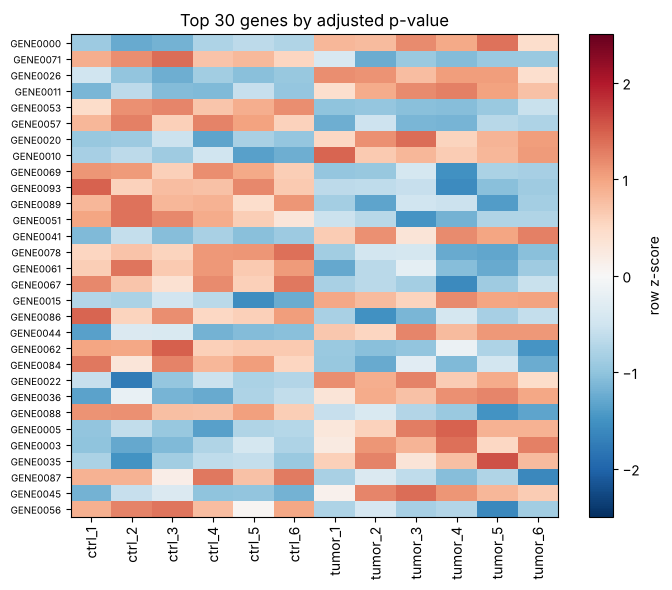

In [8]:
top = res.sort_values("padj").head(30).index
z = log_cpm.loc[top]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)

plt.figure(figsize=(7, 6))
plt.imshow(z, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
plt.colorbar(label="row z-score")
plt.xticks(range(len(samples)), samples, rotation=90)
plt.yticks(range(len(top)), top, fontsize=7)
plt.title("Top 30 genes by adjusted p-value")
plt.tight_layout()
plt.savefig("heatmap_top30.png", dpi=150)
plt.show()

## 8. Next step: real data from NCBI GEO
Pick a dataset (e.g. healthy vs. tumour tissue) on https://www.ncbi.nlm.nih.gov/geo/ and either
download its expression matrix or use the web tool GEO2R first to see what to expect.
Load the matrix into a DataFrame called `counts` (genes x samples), set the group sizes in
section 1 and rerun from section 2. Real data usually also needs filtering of low-expressed genes.